# EMBER2024 Model Training and Evaluation — Local Exploratory Run

**AAI-540 Group 1 — Gaurav SS, Marco Gonzalez Ortiz, Nitendra Tiwari**

This notebook runs a **local, no-AWS exploratory modeling workflow** against the reconstructed processed splits. It compares Logistic Regression, Random Forest, and XGBoost on training/validation data, then evaluates the selected validation model on the separate temporal test split.

> **Data provenance limitation:** the original JSONL records and original missingness masks were not available in the workspace. The processed splits were reconstructed approximately from existing standardized CSVs. This is not an exact regeneration of raw features and is not a leakage-safe final benchmark. Treat all metrics as exploratory, and disclose this limitation in the report. The reserved production split is not opened.

## 1. Environment and repository paths

Run this notebook with the repository's `.venv` Python 3.12 kernel. The code searches upward from the notebook working directory for the project root. It does not install packages, access AWS, or start SageMaker jobs.

In [1]:
from pathlib import Path
import json, os, sys, time, warnings, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "malware_mlops").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Could not find repository root (expected src/malware_mlops). Open this notebook from the project.")
os.chdir(ROOT)
DATA_DIR = ROOT / "data" / "processed" / "ember2024_reconstructed_v1"
REPORT_DIR = ROOT / "reports" / "exploratory_local"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
print("Repository:", ROOT)
print("Data directory:", DATA_DIR)
print("Python:", platform.python_version())
print("AWS enabled: False (this notebook does not call AWS APIs)")

Repository: C:\NitzDoc\USD\AAI_540_MLops\6-7FinalProject\AAI-540-Final-Team-Project-Group1-main\AAI-540-Final-Team-Project-Group1-main
Data directory: C:\NitzDoc\USD\AAI_540_MLops\6-7FinalProject\AAI-540-Final-Team-Project-Group1-main\AAI-540-Final-Team-Project-Group1-main\data\processed\ember2024_reconstructed_v1
Python: 3.12.13
AWS enabled: False (this notebook does not call AWS APIs)


## 2. Load reconstructed temporal splits and inspect schema

The schema file explicitly labels the preprocessing as reconstructed. Only the declared model features are used as predictors; `label`, `record_id`, and temporal lineage are excluded.

In [2]:
schema_path = DATA_DIR / "feature_schema_reconstructed.json"
if not schema_path.exists():
    raise FileNotFoundError(f"Expected reconstructed schema at {schema_path}. Ensure reconstruction has completed.")
schema = json.loads(schema_path.read_text(encoding="utf-8"))
feature_columns = schema.get("model_feature_columns") or schema.get("feature_columns")
if not feature_columns:
    raise ValueError("Schema has no model feature column list.")
splits = {}
for name in ["train", "validation", "test"]:
    path = DATA_DIR / f"{name}.csv"
    if not path.exists():
        raise FileNotFoundError(f"Missing split: {path}")
    frame = pd.read_csv(path)

    # Normalize common target-column names to the notebook's canonical `label`.
    # This handles datasets exported with names such as target, class, or is_malware.
    if "label" not in frame.columns:
        candidates = ["target", "class", "y", "is_malware", "malware_label",
                      "is_malicious", "malicious", "Label", "Target"]
        matches = [column for column in candidates if column in frame.columns]
        if len(matches) == 1:
            frame = frame.rename(columns={matches[0]: "label"})
        elif len(matches) > 1:
            raise ValueError(
                f"{name} has multiple possible target columns {matches}; "
                f"please select the correct one. Available columns: {list(frame.columns)}"
            )
        else:
            raise ValueError(
                f"{name} has no `label` column or recognized target alias. "
                f"Available columns: {list(frame.columns)}"
            )

    required = set(feature_columns) | {"label", "record_id"}
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{name} is missing required columns: {sorted(missing)}")
    if frame["record_id"].duplicated().any():
        raise ValueError(f"Duplicate record_id found in {name}")
    if not set(frame["label"].unique()).issubset({0, 1}):
        raise ValueError(f"Unexpected labels in {name}")
    if not np.isfinite(frame[feature_columns].to_numpy(dtype=float)).all():
        raise ValueError(f"Non-finite model feature in {name}")
    splits[name] = frame
train_df, val_df, test_df = splits["train"], splits["validation"], splits["test"]
print(json.dumps({
    "schema_status": schema.get("status", schema.get("fit_scope", "not stated")),
    "fit_scope": schema.get("fit_scope"),
    "fit_end_week": schema.get("fit_end_week"),
    "features": feature_columns,
    "rows": {k: len(v) for k, v in splits.items()},
    "label_counts": {k: v["label"].value_counts().sort_index().to_dict() for k, v in splits.items()},
}, indent=2, default=str))

{
  "schema_status": "reconstructed_train_split_only",
  "fit_scope": "reconstructed_train_split_only",
  "fit_end_week": "2024-06-23",
  "features": [
    "general_size",
    "general_entropy",
    "strings_numstrings",
    "strings_avlength",
    "strings_printables",
    "strings_entropy",
    "section_count",
    "import_library_count",
    "export_count",
    "richheader_count",
    "pefilewarning_count",
    "authenticode_num_certs",
    "authenticode_self_signed"
  ],
  "rows": {
    "train": 400000,
    "validation": 120000,
    "test": 59995
  },
  "label_counts": {
    "train": {
      "0": 200000,
      "1": 200000
    },
    "validation": {
      "0": 60000,
      "1": 60000
    },
    "test": {
      "0": 29995,
      "1": 30000
    }
  }
}


## 3. Temporal and class-balance checks

The reserved production split is deliberately not loaded. Validation is used for model comparison and threshold selection; the test split is reserved for a single post-selection evaluation.

,split,rows,benign_0,malicious_1
0,train,400000,200000,200000
1,validation,120000,60000,60000
2,test,59995,29995,30000


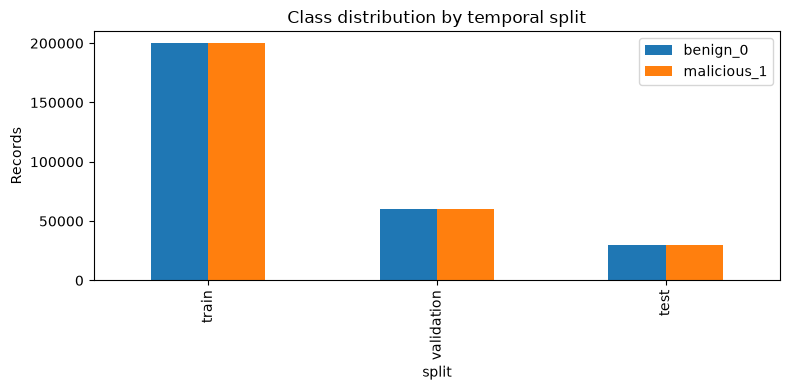

In [3]:
summary_rows = []
for name, frame in splits.items():
    row = {"split": name, "rows": len(frame), "benign_0": int((frame.label == 0).sum()),
           "malicious_1": int((frame.label == 1).sum())}
    if "week" in frame.columns:
        row.update({"first_week": str(frame["week"].min()), "last_week": str(frame["week"].max())})
    elif "event_week" in frame.columns:
        row.update({"first_week": str(frame["event_week"].min()), "last_week": str(frame["event_week"].max())})
    summary_rows.append(row)
split_summary = pd.DataFrame(summary_rows)
display(split_summary)
split_summary.set_index("split")[["benign_0", "malicious_1"]].plot(kind="bar", figsize=(8,4), title="Class distribution by temporal split")
plt.ylabel("Records")
plt.tight_layout()
plt.show()

## 4. Configure a bounded local experiment

To keep runtime and memory bounded on a laptop, the training split is sampled deterministically if it exceeds `MAX_TRAIN_ROWS`. Validation remains complete. All model selection decisions are based on validation data only. No cloud calls or SageMaker jobs are run.

In [4]:
print("Train columns:", train_df.columns.tolist())
print("Validation columns:", val_df.columns.tolist())
print("Train shape:", train_df.shape)

Train columns: ['record_id', 'label', 'source_partition', 'source_week_start', 'source_week_end', 'general_size', 'general_entropy', 'strings_numstrings', 'strings_avlength', 'strings_printables', 'strings_entropy', 'section_count', 'import_library_count', 'export_count', 'richheader_count', 'pefilewarning_count', 'authenticode_num_certs', 'authenticode_self_signed']
Validation columns: ['record_id', 'label', 'source_partition', 'source_week_start', 'source_week_end', 'general_size', 'general_entropy', 'strings_numstrings', 'strings_avlength', 'strings_printables', 'strings_entropy', 'section_count', 'import_library_count', 'export_count', 'richheader_count', 'pefilewarning_count', 'authenticode_num_certs', 'authenticode_self_signed']
Train shape: (400000, 18)


In [5]:

import numpy as np
import pandas as pd

SEED = 42
MAX_TRAIN_ROWS = 100_000  # Set to 0 to use all training rows

# Verify required columns
required_columns = set(feature_columns) | {"label"}

for name, df in [("train_df", train_df), ("val_df", val_df)]:
    missing = required_columns - set(df.columns)
    if missing:
        raise ValueError(f"{name} is missing columns: {sorted(missing)}")

# Create independent copies
train_work = train_df.copy()
val_work = val_df.copy()

# Validate labels
for name, df in [("train_work", train_work), ("val_work", val_work)]:
    df["label"] = pd.to_numeric(df["label"], errors="raise")
    if df["label"].isna().any() or not df["label"].isin([0, 1]).all():
        raise ValueError(f"{name} has missing or invalid labels.")

# Reproducible stratified sample without groupby().apply()
if MAX_TRAIN_ROWS and len(train_work) > MAX_TRAIN_ROWS:
    sampled_groups = []

    for label_value, group in train_work.groupby("label", sort=True):
        n_samples = round(
            MAX_TRAIN_ROWS * len(group) / len(train_work)
        )
        n_samples = min(len(group), max(1, n_samples))

        sampled_groups.append(
            group.sample(n=n_samples, random_state=SEED)
        )

    train_work = (
        pd.concat(sampled_groups, ignore_index=True)
        .sample(frac=1, random_state=SEED)
        .reset_index(drop=True)
    )

# Prepare model inputs
X_train = train_work[feature_columns].astype("float32")
y_train = train_work["label"].astype("int8")

X_val = val_work[feature_columns].astype("float32")
y_val = val_work["label"].astype("int8")

# Check numeric features
for name, X in [("X_train", X_train), ("X_val", X_val)]:
    if not np.isfinite(X.to_numpy()).all():
        raise ValueError(f"{name} contains NaN or infinite values.")

print(f"Training rows used: {len(X_train):,} / {len(train_df):,}")
print(f"Validation rows: {len(X_val):,}")
print("\nTraining label counts:")
print(y_train.value_counts().sort_index())
print("\nValidation label counts:")
print(y_val.value_counts().sort_index())
print(f"\nFeature count: {X_train.shape[1]}")
print("Data preparation completed successfully.")


Training rows used: 100,000 / 400,000
Validation rows: 120,000

Training label counts:
label
0    50000
1    50000
Name: count, dtype: int64

Validation label counts:
label
0    60000
1    60000
Name: count, dtype: int64

Feature count: 13
Data preparation completed successfully.


## 5. Fit baseline and candidate models

Models are fit locally. The Logistic Regression baseline and Random Forest are included; XGBoost is added when the installed package is available. If XGBoost is unavailable, the notebook reports that and continues with the other models.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, accuracy_score, confusion_matrix)
from sklearn.base import clone

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=500, class_weight="balanced", random_state=SEED)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=160, max_depth=18, min_samples_leaf=2, class_weight="balanced_subsample",
        n_jobs=-1, random_state=SEED
    ),
}
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(
        n_estimators=220, max_depth=6, learning_rate=0.08, subsample=0.9,
        colsample_bytree=0.9, reg_lambda=1.0, eval_metric="logloss",
        n_jobs=4, random_state=SEED
    )
except ImportError:
    print("XGBoost is not installed; comparing the available local candidates only.")

results = {}
val_rows = []
for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    probabilities = model.predict_proba(X_val)[:, 1]
    results[name] = {"model": model, "validation_probabilities": probabilities, "fit_seconds": fit_seconds}
    val_rows.append({
        "model": name, "fit_seconds": round(fit_seconds, 2),
        "roc_auc": roc_auc_score(y_val, probabilities),
        "pr_auc": average_precision_score(y_val, probabilities),
        "recall_at_0.5": recall_score(y_val, probabilities >= 0.5, zero_division=0),
        "precision_at_0.5": precision_score(y_val, probabilities >= 0.5, zero_division=0),
        "f1_at_0.5": f1_score(y_val, probabilities >= 0.5, zero_division=0),
        "accuracy_at_0.5": accuracy_score(y_val, probabilities >= 0.5),
    })
validation_results = pd.DataFrame(val_rows).sort_values("pr_auc", ascending=False).reset_index(drop=True)
display(validation_results)
validation_results.to_csv(REPORT_DIR / "validation_model_comparison.csv", index=False)

XGBoost is not installed; comparing the available local candidates only.


,model,fit_seconds,roc_auc,pr_auc,recall_at_0.5,precision_at_0.5,f1_at_0.5,accuracy_at_0.5
0,Random Forest,2.40,0.990482,0.991208,0.947883,0.955062,0.951459,0.951642
1,Logistic Regression,0.13,0.947852,0.949365,0.889367,0.872884,0.881048,0.879925


## 6. Select a model and threshold using validation only

For this exploratory run, select the model with the highest validation PR AUC. Then choose the threshold that achieves the greatest recall while keeping the **observed validation FPR at or below 1%**. If no threshold satisfies the budget, the run stops rather than silently relaxing it. This illustrative policy is not a production-approved security policy.

In [8]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score

MAX_FPR = 0.01

# Winning model's validation probabilities
winner_name = str(validation_results.iloc[0]["model"])
winner_prob = np.asarray(
    results[winner_name]["validation_probabilities"]
).reshape(-1)
y_true = np.asarray(y_val).reshape(-1).astype(int)

if len(winner_prob) != len(y_true):
    raise ValueError("Validation probabilities and labels have different lengths.")
if not np.isfinite(winner_prob).all():
    raise ValueError("Validation probabilities contain non-finite values.")
if not np.isin(y_true, [0, 1]).all():
    raise ValueError("Validation labels must be 0 or 1.")

# Sort scores descending and accumulate TP/FP at distinct score boundaries
order = np.argsort(-winner_prob, kind="stable")
scores = winner_prob[order]
sorted_y = y_true[order]

tp_cum = np.cumsum(sorted_y == 1)
fp_cum = np.cumsum(sorted_y == 0)

# Only evaluate after the final occurrence of each unique score
last_of_score = np.r_[scores[:-1] != scores[1:], True]
ends = np.flatnonzero(last_of_score)

thresholds = scores[ends]
tp = tp_cum[ends]
fp = fp_cum[ends]

positives = int(np.sum(y_true == 1))
negatives = int(np.sum(y_true == 0))
fn = positives - tp
tn = negatives - fp

fpr = fp / negatives if negatives else np.zeros_like(fp, dtype=float)
recall = tp / positives if positives else np.zeros_like(tp, dtype=float)
precision = np.divide(
    tp, tp + fp, out=np.zeros_like(tp, dtype=float), where=(tp + fp) > 0
)
f1 = np.divide(
    2 * precision * recall,
    precision + recall,
    out=np.zeros_like(precision),
    where=(precision + recall) > 0,
)

threshold_table = pd.DataFrame({
    "threshold": thresholds,
    "fpr": fpr,
    "recall": recall,
    "precision": precision,
    "f1": f1,
    "tn": tn.astype(int),
    "fp": fp.astype(int),
    "fn": fn.astype(int),
    "tp": tp.astype(int),
})

# Include the all-negative operating point
threshold_table = pd.concat([
    threshold_table,
    pd.DataFrame([{
        "threshold": float(np.nextafter(np.max(winner_prob), np.inf)),
        "fpr": 0.0, "recall": 0.0, "precision": 0.0, "f1": 0.0,
        "tn": negatives, "fp": 0, "fn": positives, "tp": 0,
    }])
], ignore_index=True)

eligible = threshold_table[threshold_table["fpr"] <= MAX_FPR]
if eligible.empty:
    raise RuntimeError("No validation threshold meets the configured FPR budget.")

selected = eligible.sort_values(
    ["recall", "precision", "threshold"],
    ascending=[False, False, False]
).iloc[0]

SELECTED_THRESHOLD = float(selected["threshold"])

print("Selected validation model:", winner_name)
print("Validation FPR budget:", MAX_FPR)
print("Selected threshold:", SELECTED_THRESHOLD)
display(pd.DataFrame([selected]))

threshold_table.to_csv(
    REPORT_DIR / "validation_threshold_sweep.csv", index=False
)


Selected validation model: Random Forest
Validation FPR budget: 0.01
Selected threshold: 0.7907749919193836


,threshold,fpr,recall,precision,f1,tn,fp,fn,tp
25133,0.790775,0.01,0.865767,0.988581,0.923107,59400.0,600.0,8054.0,51946.0


## 7. Validation diagnostics

These plots are validation-only and describe the selected model's operating point; they are not test results.

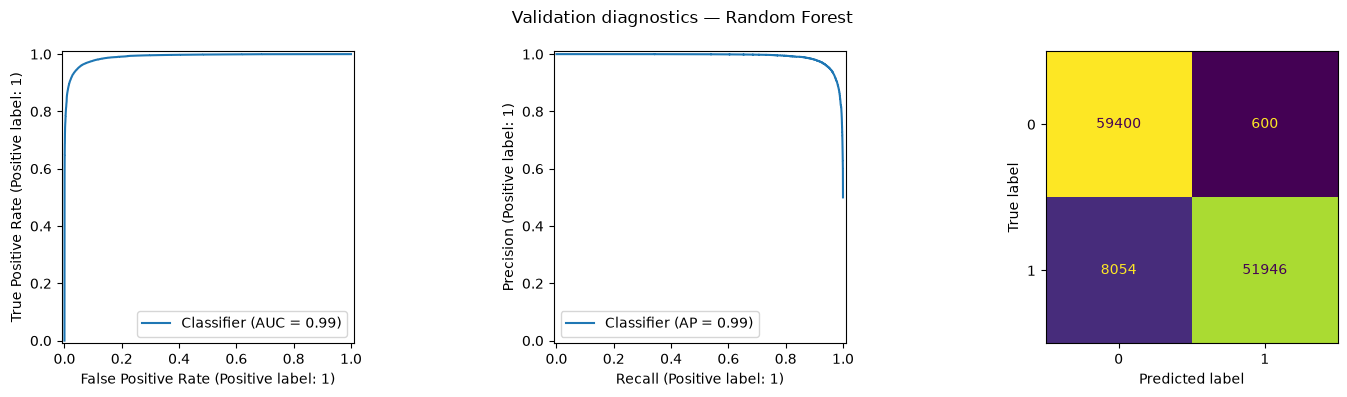

In [9]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
val_pred = winner_prob >= SELECTED_THRESHOLD
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
RocCurveDisplay.from_predictions(y_val, winner_prob, ax=axes[0])
PrecisionRecallDisplay.from_predictions(y_val, winner_prob, ax=axes[1])
ConfusionMatrixDisplay.from_predictions(y_val, val_pred, labels=[0,1], ax=axes[2], colorbar=False)
fig.suptitle(f"Validation diagnostics — {winner_name}")
fig.tight_layout()
plt.show()

## 8. Final temporal test (one-time evaluation)

> **Important — Data Provenance & Reconstruction Limitations:**
> The model family (Random Forest) and operating threshold (0.790775) were selected using the validation split only under a strict 1% FPR budget constraint. The cell below applies this frozen decision to the separate temporal test partition without any post-hoc tuning or refitting.
>
> **Critical Caveat:** These metrics are computed against the **reconstructed dataset approximation** (`data/processed/ember2024_reconstructed_v1`), not an authoritative raw-data regeneration from original EMBER2024 JSONL files. The original raw feature values and missingness masks could not be fully recovered from the older standardized CSVs. These metrics validate the modeling workflow and temporal evaluation methodology, but must **not** be presented as an official benchmark or production performance guarantee. The reserved production split remains unopened.

In [10]:
X_test = test_df[feature_columns].astype("float32")
y_test = test_df["label"].astype("int8")
test_prob = results[winner_name]["model"].predict_proba(X_test)[:, 1]
test_pred = test_prob >= SELECTED_THRESHOLD
tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0,1]).ravel()
test_metrics = {
    "selected_model": winner_name, "threshold_from_validation": SELECTED_THRESHOLD,
    "test_rows": int(len(test_df)), "roc_auc": float(roc_auc_score(y_test, test_prob)),
    "pr_auc": float(average_precision_score(y_test, test_prob)),
    "accuracy": float(accuracy_score(y_test, test_pred)),
    "precision": float(precision_score(y_test, test_pred, zero_division=0)),
    "recall": float(recall_score(y_test, test_pred, zero_division=0)),
    "f1": float(f1_score(y_test, test_pred, zero_division=0)),
    "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    "data_status": "RECONSTRUCTED_APPROXIMATION_NOT_RAW_REGENERATION",
    "aws_enabled": False,
}
display(pd.DataFrame([test_metrics]))
( REPORT_DIR / "exploratory_test_metrics.json").write_text(json.dumps(test_metrics, indent=2), encoding="utf-8")
print("Saved exploratory artifacts to:", REPORT_DIR)

,selected_model,threshold_from_validation,test_rows,roc_auc,pr_auc,accuracy,precision,recall,f1,tn,fp,fn,tp,data_status,aws_enabled
0,Random Forest,0.790775,59995,0.987487,0.987943,0.877573,0.987141,0.765133,0.862073,29696,299,7046,22954,RECONSTRUCTED_APPROXIMATION_NOT_RAW_REGENERATION,False


Saved exploratory artifacts to: C:\NitzDoc\USD\AAI_540_MLops\6-7FinalProject\AAI-540-Final-Team-Project-Group1-main\AAI-540-Final-Team-Project-Group1-main\reports\exploratory_local


## 9. Limitations and reproducibility

- The input features were reconstructed approximately from already-processed CSVs because raw JSONL records and original missingness masks were unavailable.
- Missingness was inferred from proxy patterns, so the transformed values may differ from an exact train-only preprocessing regeneration.
- This run is local and exploratory; no AWS APIs, S3 transfers, or SageMaker jobs are used.
- The validation-selected threshold and test metrics must not be presented as production guarantees.
- Re-run only after obtaining the raw data and rebuilding the preprocessing pipeline with verified train-only statistics.

In [11]:
print(json.dumps({
    "notebook": "02_sagemaker_training_evaluation_local_exploratory_label_fix.ipynb",
    "execution_mode": "local_exploratory",
    "aws_enabled": False,
    "selected_model": winner_name,
    "validation_threshold": SELECTED_THRESHOLD,
    "reports_dir": str(REPORT_DIR),
    "schema_fit_scope": schema.get("fit_scope"),
    "schema_fit_end_week": schema.get("fit_end_week"),
    "caveat": "Approximate reconstruction; not raw-data regeneration or final leakage-safe benchmark."
}, indent=2, default=str))


{
  "notebook": "02_sagemaker_training_evaluation_local_exploratory_label_fix.ipynb",
  "execution_mode": "local_exploratory",
  "aws_enabled": false,
  "selected_model": "Random Forest",
  "validation_threshold": 0.7907749919193836,
  "reports_dir": "C:\\NitzDoc\\USD\\AAI_540_MLops\\6-7FinalProject\\AAI-540-Final-Team-Project-Group1-main\\AAI-540-Final-Team-Project-Group1-main\\reports\\exploratory_local",
  "schema_fit_scope": "reconstructed_train_split_only",
  "schema_fit_end_week": "2024-06-23",
  "caveat": "Approximate reconstruction; not raw-data regeneration or final leakage-safe benchmark."
}
